/tmp/ipykernel_114234/2362926339.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = get_cmap("viridis")


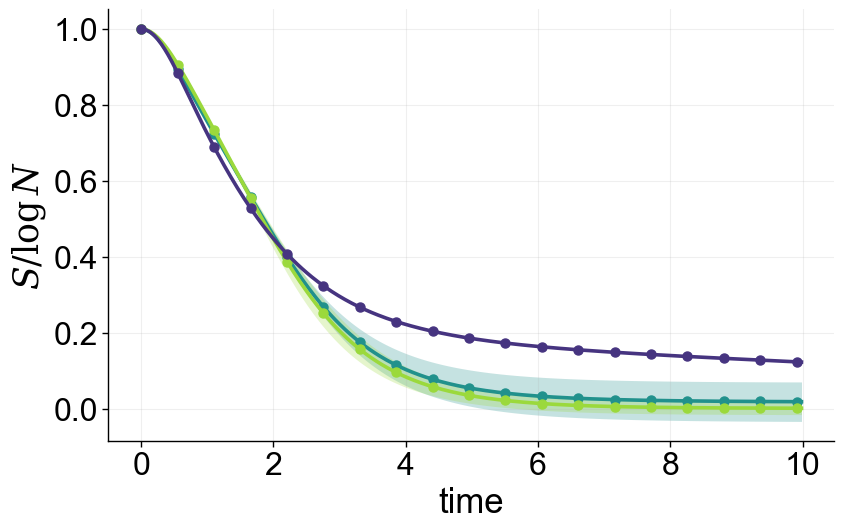

/tmp/ipykernel_114234/2362926339.py:216: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.6)


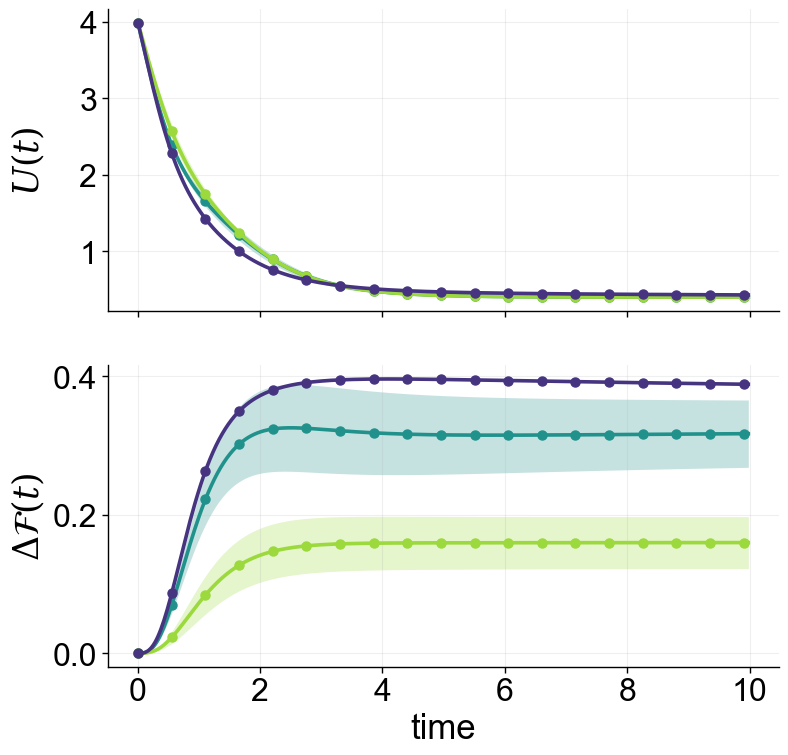

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.lines import Line2D

# =====================================================
# Style: Arial text + DejaVu Serif math
# Default fontsize = 25
# =====================================================
FONT_SIZE = 25

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,

    "axes.titlesize": FONT_SIZE + 1,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,
    "xtick.labelsize": FONT_SIZE - 2,
    "ytick.labelsize": FONT_SIZE - 2,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,

    "legend.fontsize": FONT_SIZE - 2,
    "legend.frameon": False,

    "mathtext.fontset": "dejavuserif",
    "mathtext.rm": "DejaVu Serif",
    "mathtext.it": "DejaVu Serif:italic",
    "mathtext.bf": "DejaVu Serif:bold",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

viridis = get_cmap("viridis")

# =====================================================
# FILES (EPI)
# =====================================================
cm_file   = "thermo_noisy_cm_good_final.npz"
er_file   = "thermo_noisy_er_good_final.npz"
dd_file   = "dthermo_noisy_d.npz"
traj_file = "dtraj_noisy_d.npz"   # optional for N inference
out_tag   = "noisy"

# =====================================================
# LOAD
# =====================================================
cm = np.load(cm_file, allow_pickle=True)
er = np.load(er_file, allow_pickle=True)
dd = np.load(dd_file, allow_pickle=True)

taus_samp   = cm["taus_samp"]
t_data_full = dd["t"]

idx_data = np.array([np.argmin(np.abs(t_data_full - ts)) for ts in taus_samp], dtype=int)

S_cm  = cm["entropy"]
E_cm  = cm["energy"]
KL_cm = cm["divergence"]

S_er  = er["entropy"]
E_er  = er["energy"]
KL_er = er["divergence"]

S_d_full  = dd["S"]
E_d_full  = dd["E"]
KL_d_full = dd["div"]

S_d  = S_d_full[idx_data]
E_d  = E_d_full[idx_data]
KL_d = KL_d_full[idx_data]

assert S_d.shape[0] == taus_samp.shape[0]
assert E_d.shape[0] == taus_samp.shape[0]
assert KL_d.shape[0] == taus_samp.shape[0]

# =====================================================
# Normalize entropy by 1/log N (if possible)
# =====================================================
norm = None
try:
    tr = np.load(traj_file, allow_pickle=True)
    x = tr["x"]
    N = x.shape[0]
    norm = 1.0 / np.log(N)
except Exception:
    norm = None

if norm is None:
    print("[WARN] Could not infer N for S/logN normalization. Set N manually if needed.")
else:
    S_cm *= norm
    S_er *= norm
    S_d  *= norm

# =====================================================
# Derived: KL(t)/t
# =====================================================
Fdiff_cm = KL_cm / taus_samp[None, :]
Fdiff_er = KL_er / taus_samp[None, :]
Fdiff_d  = KL_d  / taus_samp

# =====================================================
# Mean/std helpers
# =====================================================
def mean_std(arr_2d):
    mu = np.nanmean(arr_2d, axis=0)
    sd = np.nanstd(arr_2d, axis=0, ddof=1)
    return mu, sd

S_cm_mu, S_cm_sd = mean_std(S_cm)
S_er_mu, S_er_sd = mean_std(S_er)
E_cm_mu, E_cm_sd = mean_std(E_cm)
E_er_mu, E_er_sd = mean_std(E_er)
F_cm_mu, F_cm_sd = mean_std(Fdiff_cm)
F_er_mu, F_er_sd = mean_std(Fdiff_er)

# =====================================================
# Plot settings
# =====================================================
lw = 2.6
ms = 6.5
markevery = max(1, len(taus_samp) // 18)

shade_alpha = 0.26

c_data = viridis(0.15)
c_cm   = viridis(0.50)
c_er   = viridis(0.85)

# Base size for single panels
fig_width  = 220 / 25.4   # ~8.66 in
fig_height = 140 / 25.4   # ~5.51 in

def plot_with_band(ax, t, mu, sd, color):
    ax.plot(t, mu, color=color, lw=lw, marker="o", ms=ms, markevery=markevery)
    ax.fill_between(t, mu - sd, mu + sd, color=color, alpha=shade_alpha, linewidth=0)

def plot_data_sparse(ax, t, y, color):
    ax.plot(t, y, color=color, lw=lw)
    ax.plot(t, y, color=color, lw=0, marker="o", ms=ms, markevery=markevery)

def format_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)
    ax.tick_params(direction="out")

# =====================================================
# Separate legend (PDF)
# =====================================================
def save_legend_pdf(filename):
    handles = [
        Line2D([0], [0], color=c_cm,   lw=lw, marker="o", ms=ms, label="CM (mean ± std)"),
        Line2D([0], [0], color=c_er,   lw=lw, marker="o", ms=ms, label="ER (mean ± std)"),
        Line2D([0], [0], color=c_data, lw=lw, marker="o", ms=ms, label="Data"),
    ]
    fig_leg = plt.figure(figsize=(6.0, 2.2))
    fig_leg.legend(handles=handles, loc="center", ncol=3, frameon=False, handlelength=2.0)
    fig_leg.tight_layout(pad=0.2)
    fig_leg.savefig(filename, format="pdf", bbox_inches="tight")
    plt.close(fig_leg)

save_legend_pdf(f"legend_{out_tag}.pdf")

# =====================================================
# FIGURE A — ENTROPY
# =====================================================
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
plot_with_band(ax, taus_samp, S_cm_mu, S_cm_sd, c_cm)
plot_with_band(ax, taus_samp, S_er_mu, S_er_sd, c_er)
plot_data_sparse(ax, taus_samp, S_d, c_data)
ax.set_xlabel("time")
ax.set_ylabel(r"$S/\log N$" if norm is not None else r"$S$")
format_axes(ax)
fig.tight_layout(pad=0.6)
fig.savefig(f"fig_entropy_{out_tag}_compare.pdf", format="pdf", bbox_inches="tight")
plt.show()

# =====================================================
# FIGURE B+C — ENERGY (top) + ΔF(t) (bottom)
# =====================================================
fig_height_2 = 1.55 * fig_height

fig, (ax1, ax2) = plt.subplots(
    nrows=2, ncols=1,
    figsize=(fig_width, fig_height_2),
    sharex=True,
    gridspec_kw={"hspace": 0.18}
)

# ---- Top: ENERGY
plot_with_band(ax1, taus_samp, E_cm_mu, E_cm_sd, c_cm)
plot_with_band(ax1, taus_samp, E_er_mu, E_er_sd, c_er)
plot_data_sparse(ax1, taus_samp, E_d, c_data)
ax1.set_ylabel(r"$U(t)$")
format_axes(ax1)
ax1.set_xlabel("")
ax1.tick_params(labelbottom=False)

# ---- Bottom: ΔF(t)
plot_with_band(ax2, taus_samp, F_cm_mu, F_cm_sd, c_cm)
plot_with_band(ax2, taus_samp, F_er_mu, F_er_sd, c_er)
plot_data_sparse(ax2, taus_samp, Fdiff_d, c_data)
ax2.set_xlabel("time")
ax2.set_ylabel(r"$\Delta\mathcal{F}(t)$")
format_axes(ax2)

# ---- Layout + y-label alignment
fig.tight_layout(pad=0.6)
fig.align_ylabels([ax1, ax2])

fig.savefig(
    f"fig_energy_and_free_energy_diff_{out_tag}_compare.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()
